Today's topics:
* color as a third variable in a scatter plot
* contour maps with `tricontourf`

# 3D printed parts

A [fused deposition](https://en.wikipedia.org/wiki/Fused_filament_fabrication) printer melts a plastic filament and lays it down one bead at a time.
The printer builds the part layer by layer.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/ad/RepRap_printing_closeup.jpg/960px-RepRap_printing_closeup.jpg" alt="Close-up of a fused-deposition printer in operation, with a brass nozzle above three red parts whose deposited layers are visible" width=520/>

Photo by Emmanuel Gilloz, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:RepRap_printing_closeup.jpg).

The horizontal lines on the parts are the deposited layers.

The table records nine printer settings and three measured outcomes.
We'll focus on two settings today.
- `layer_height (mm)` is the height of one bead
- `wall_thickness (mm)` is the thickness of the outer shell

Each finished part has a measured side-wall `roughness (microns)` and a `tension_strength (Mpa)` from a tensile test.

We'll use 50 prints from [Ahmet Okudan's 3D printer dataset](https://github.com/ahmetokudan/3dprinterdeeplearning), released for unrestricted use.
These come from a different study than the printed-part compression test.

Both outcomes vary with several settings at once.
Which combinations go with smoother, stronger parts in this table?

A plot has two axes, so how do we show a third setting?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/3dprinting.csv'
data = pd.read_csv(url)
print(len(data), 'prints')

50 prints


Let's give the columns we need short names.

In [2]:
layer = data['layer_height (mm)']
wall = data['wall_thickness (mm)']
rough = data['roughness (microns)']

We'll start with a plot we know: roughness against layer height.

Text(0, 0.5, 'roughness (microns)')

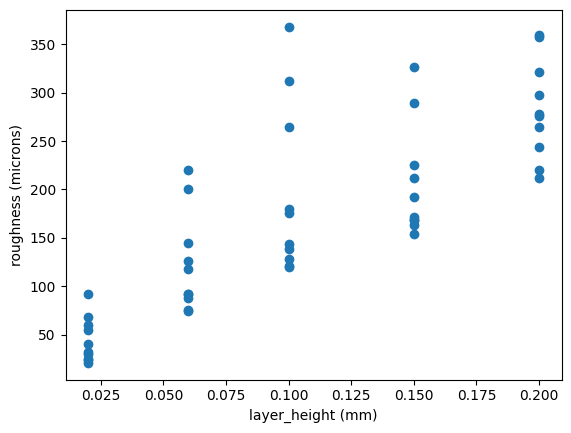

In [3]:
fig, ax = plt.subplots()
ax.scatter(layer, rough)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)

Roughness rises with layer height.
Where does wall thickness fit in?

# Color as a third variable

## One series per value

We already know one way to add a third variable.
We draw a separate series for each value and label it.

Wall thickness takes ten values, so let's list them and loop over the list with a mask.

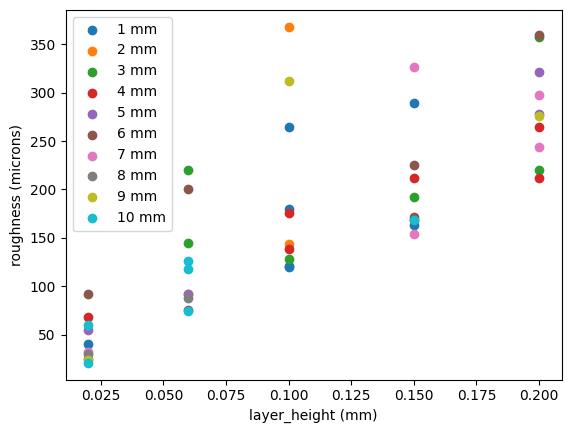

In [4]:
walls = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  # mm

fig, ax = plt.subplots()
for t in walls:
    mask = wall == t
    ax.scatter(layer.loc[mask], rough.loc[mask], label=f'{t} mm')
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
ax.legend()

Wall thickness runs from 1 to 10 mm, so let's encode that order with shades from light to dark.

## The `c` keyword

`ax.scatter` takes a keyword `c` for the color of each marker.
We give it one number per print, here the wall thickness.

The keyword `cmap` sets the **colormap**, the scale that turns numbers into colors.
`'Greys'` runs from white at the lowest value to black at the highest, which suits a greyscale printout.

The lightest markers would blend into the white background, so `edgecolor='k'` outlines every marker in black.

Text(0, 0.5, 'roughness (microns)')

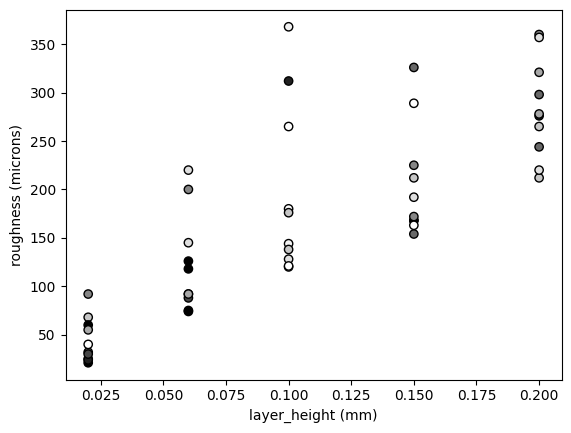

In [5]:
fig, ax = plt.subplots()
ax.scatter(layer, rough, c=wall, cmap='Greys', edgecolor='k')
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)

## A colorbar

A **colorbar** pairs each shade with a number.
`ax.scatter` returns the object that stores the colormap and the range of values, so let's save it as `im` and pass it to `fig.colorbar`.

The colorbar is an object too, and its `set_label` method works like `ax.set_xlabel`.

Text(0, 0.5, 'roughness (microns)')

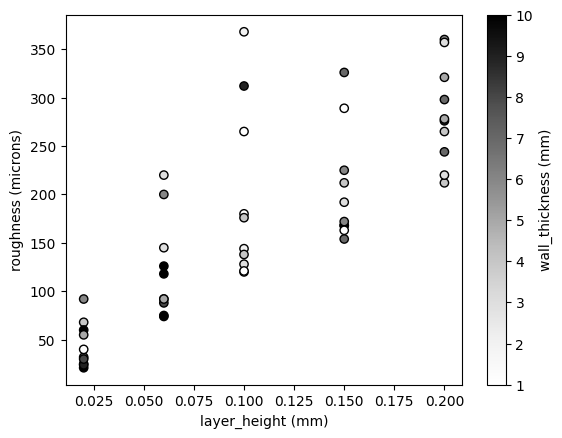

In [6]:
fig, ax = plt.subplots()
im = ax.scatter(layer, rough, c=wall, cmap='Greys', edgecolor='k')
cb = fig.colorbar(im, ax=ax)  # ax names the axes that gets the bar
cb.set_label(wall.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)

> We'll use `fig.colorbar(im, ax=ax)` so the call names the axes that owns the colorbar.

Roughness climbs with layer height, and the shades are mixed at every layer height.

### [Check your understanding]

Let's see which settings go with a strong part.

1. Make a `fig, ax` and an `ax.scatter` with `infill_density (%)` on the x axis and `wall_thickness (mm)` on the y axis.
2. Color the markers by `tension_strength (Mpa)` with `cmap='Greys'` and `edgecolor='k'`.
3. Save the result of `ax.scatter` as `im`, add a colorbar with `fig.colorbar(im, ax=ax)`, and label it with `set_label`.
4. Label the x and y axes.

*Where are the darkest markers, and which combination of settings goes with the highest strengths in this table?*

Optional challenge: put `nozzle_temperature (degC)` on the y axis instead.

# Contour maps

Color shows a value at each print.
For an outcome like roughness, we may want a value at every combination of the two settings.

A topographic map does this for land.
Each line joins points of equal elevation, and where lines bunch together the ground is steep.

A **contour** map does the same for any quantity.
Our two axes are the settings, and the elevation is roughness.

`ax.tricontourf` takes three columns of the same length: `x`, `y`, and the value `z`.
The `f` stands for filled.

It joins the prints into triangles and interpolates `z` across each triangle.
Then it fills a band of color for each range of `z`.

`ax.tricontour` draws only the lines between bands, and black lines keep the bands visible on paper.

Like `ax.scatter`, `ax.tricontourf` returns an object that `fig.colorbar` can use.

We'll draw the 50 prints on top with the same colormap.

Text(0, 0.5, 'wall_thickness (mm)')

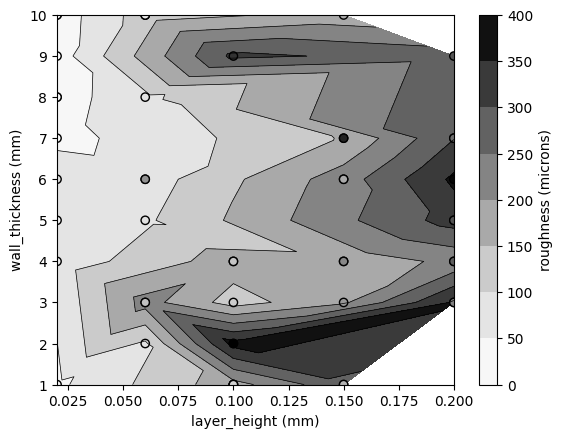

In [7]:
fig, ax = plt.subplots()
cs = ax.tricontourf(layer, wall, rough, cmap='Greys')
ax.tricontour(layer, wall, rough, colors='k', linewidths=0.5)  # black lines at the band edges
ax.scatter(layer, wall, c=rough, cmap='Greys', edgecolor='k')  # the prints, drawn over the map
cb = fig.colorbar(cs, ax=ax)
cb.set_label(rough.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(wall.name)

The lines run mostly up and down, with some bends.
Roughness changes mainly as we move along the layer height axis, and much less as we move up the wall thickness axis.

Most markers match the band behind them, and a few don't.

## Where a marker and the map differ

The map comes from triangles between the sampled locations, so it's an interpolation.
At a location we sampled twice, there are two measured values and the map shows one.

Let's look at the prints made at a layer height of 0.1 mm and a wall thickness of 1 mm.
We join the two comparisons with `&`.

In [8]:
same = (layer == 0.1) & (wall == 1)
print(data.loc[same, ['material', 'nozzle_temperature (degC)', 'roughness (microns)']])

   material  nozzle_temperature (degC)  roughness (microns)
20      abs                        220                  120
22      abs                        230                  265
25      pla                        200                  180
29      pla                        220                  121


Four prints share the same two settings and differ in the others, and their roughness differs too.
A map of two settings has one value at each location, while these four prints have four different roughness values.

### [Check your understanding]

Let's try a different second setting.
The cell below draws a filled contour map of roughness over layer height and nozzle temperature.

1. Label the x and y axes.
2. Draw the 50 prints on top with `ax.scatter`, colored by roughness with `cmap='Greys'` and `edgecolor='k'`.
3. Compare this contour with the layer height and wall thickness contour.

*Across these sampled ranges, which input is more strongly associated with roughness, and how do the band edges show it?*

Optional challenge: repeat with `tension_strength (Mpa)` in place of roughness.

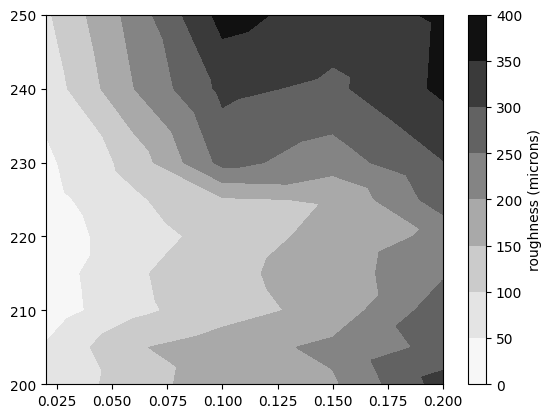

In [9]:
nozzle = data['nozzle_temperature (degC)']

fig, ax = plt.subplots()
cs = ax.tricontourf(layer, nozzle, rough, cmap='Greys')
cb = fig.colorbar(cs, ax=ax)
cb.set_label(rough.name)

# Summary

On color as a third variable:
* `c=` gives `ax.scatter` one number per marker to turn into a color.
* `cmap='Greys'` runs from white at the lowest value to black at the highest, and `edgecolor='k'` keeps the light markers visible.
* `im = ax.scatter(...)` saves the object that `fig.colorbar(im, ax=ax)` needs, and `cb.set_label` names the quantity.

On contour maps:
* `ax.tricontourf(x, y, z)` fills bands of equal `z` across the plane of the two settings.
* The bands come from triangles between the prints, so the map interpolates the sampled locations.
* Band edges that run up and down mean `z` changes mainly along x.

On our question about printed parts:
* In these 50 prints, roughness is strongly associated with layer height and weakly associated with wall thickness.
* The colored scatter shows where high-strength prints fall for the two settings on its axes.

## Further reading

* [`matplotlib.axes.Axes.scatter` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html), which lists `s`, `c`, `cmap`, and `edgecolor`
* [`matplotlib.figure.Figure.colorbar` documentation](https://matplotlib.org/stable/api/figure_api.html#matplotlib.figure.Figure.colorbar)
* [`matplotlib.axes.Axes.tricontourf` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.tricontourf.html)
* [Choosing colormaps in Matplotlib](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
* Okudan, A. 3D printer dataset. https://github.com/ahmetokudan/3dprinterdeeplearning
* Photo credit: fused deposition printer, Emmanuel Gilloz, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:RepRap_printing_closeup.jpg)

# Appendix A: Marker size and other colormaps

Optional.

The keyword `s` sets the size of each marker, so it can show a fourth variable.
Here the size follows wall thickness, and the shade follows tension strength.

Text(0, 0.5, 'roughness (microns)')

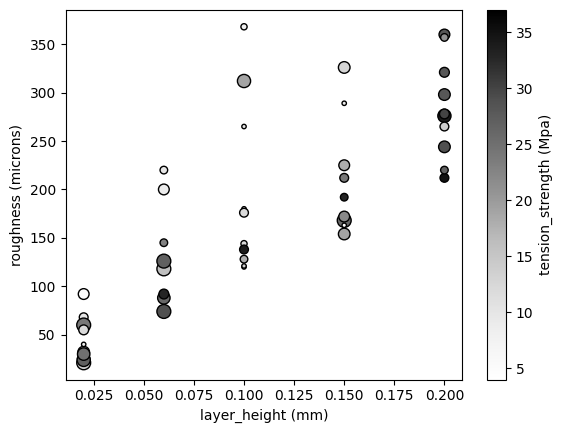

In [10]:
strength = data['tension_strength (Mpa)']

fig, ax = plt.subplots()
im = ax.scatter(layer, rough, s=10 * wall, c=strength, cmap='Greys', edgecolor='k')
cb = fig.colorbar(im, ax=ax)
cb.set_label(strength.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)

Marker size is hard to compare across a plot, so I use it sparingly.

When we leave out `cmap`, matplotlib uses a colormap called `'viridis'`.
Here is the same plot with it.

Text(0, 0.5, 'roughness (microns)')

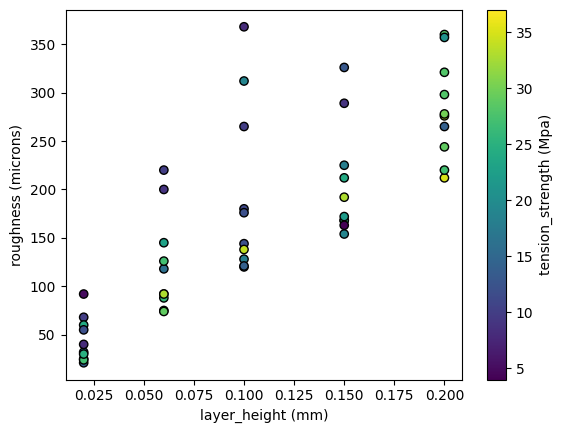

In [11]:
fig, ax = plt.subplots()
im = ax.scatter(layer, rough, c=strength, cmap='viridis', edgecolor='k')
cb = fig.colorbar(im, ax=ax)
cb.set_label(strength.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)

And here it is with `'Greys'`.

Text(0, 0.5, 'roughness (microns)')

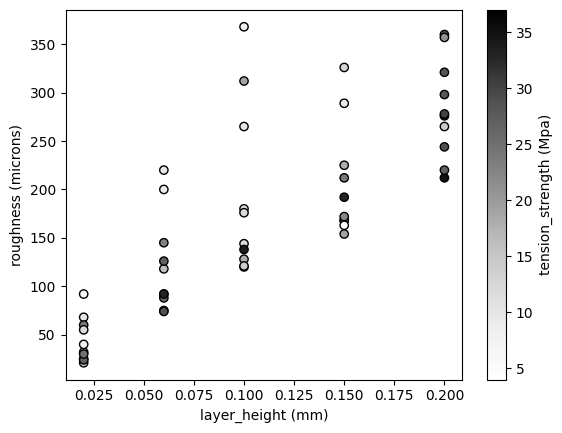

In [12]:
fig, ax = plt.subplots()
im = ax.scatter(layer, rough, c=strength, cmap='Greys', edgecolor='k')
cb = fig.colorbar(im, ax=ax)
cb.set_label(strength.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)

I use `'Greys'` for any figure that might be printed.
Colormaps run from the lowest value to the highest, so every figure with one needs a colorbar.